# Figure 4 — presentation reveals

Run all cells in order. Each output adds one **line type across all three sites**:

1. Black station-observation lines (with PPSA snow-pit markers).
2. Blue HRRR-AK forcing lines.
3. Green mixed-met forcing lines.

An empty-panel output is included first. Each stage retains everything revealed
previously. Edit `reveal_groups` below to change the sequence.

The original Figure 4 data, styling, 14 × 12 inch size, and 300 dpi are retained.
Axes, titles, ticks, and legend positions are fixed from the complete figure.
Legend entries appear with their series, with their space reserved from the start.
Every output uses the same full canvas (4200 × 3600 pixels), so paste each image
at the same size and position in PowerPoint. Each reveal is exported as `figure4_presentation_step0` through `step3` (PNG/PDF) in `figures/files/`, retaining the fixed canvas.

Uses the same local data paths and Python environment as `figure4.ipynb`.


In [1]:
# Locate figure exports from the repo root, figures/, or figures/scripts/.
from pathlib import Path
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'envs' / 'rasterio.yml').is_file() and (p / 'figures').is_dir())
FIGURE_FILES = REPO_ROOT / 'figures' / 'files'
FIGURE_FILES.mkdir(parents=True, exist_ok=True)

# import packages 
%matplotlib inline

# plotting packages 
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns 
import matplotlib.dates as mdates

sns.set_theme()
plt.rcParams['figure.figsize'] = [12,6] #overriding size

# data packages 
import pandas as pd
import numpy as np
import xarray as xr
from datetime import datetime

import scipy
import os

Run with the same **xarray** environment used by the original notebook.

# Open Data and Model Simulations

## Function for Reading SMET Files 

In [2]:
def read_smet(filepath):
    header = {}
    fields = None
    data_start = None

    # Read file and parse header
    with open(filepath, "r") as f:
        lines = f.readlines()

    for i, line in enumerate(lines):
        line = line.strip()

        # Detect fields line
        if line.startswith("fields"):
            fields = line.split("=")[1].strip().split()

        # Detect start of data
        if line == "[DATA]":
            data_start = i + 1
            break

        # Parse header key-value pairs
        if "=" in line and not line.startswith("["):
            key, value = line.split("=", 1)
            header[key.strip()] = value.strip()

    if fields is None:
        raise ValueError("No 'fields' line found in SMET header.")
    if data_start is None:
        raise ValueError("No [DATA] section found.")

    # Read data into DataFrame
    df = pd.read_csv(
        filepath,
        skiprows=data_start,
        delim_whitespace=True,
        names=fields,
        parse_dates=["timestamp"]
    )

    # Set timestamp as index
    df = df.set_index("timestamp")

    # Convert to xarray
    ds = xr.Dataset.from_dataframe(df)

    return ds, header

### Open SNOWPACK SMet Output

In [3]:
# HRRR-AK Files First 
ds_snowpack_hrrrak_ppsa, header_hrrrak_ppsa = read_smet("/home/cassie/python/models/run_snowpack/sites/ppsa/output/hrrrak_ppsa_WY2020-WY2025_base.smet")
ds_snowpack_hrrrak_tram, header_hrrrak_tram = read_smet("/home/cassie/python/models/run_snowpack/sites/tram/output/hrrrak_tram_WY2020-WY2025_base.smet")
ds_snowpack_hrrrak_heen, header_hrrrak_heen = read_smet("/home/cassie/python/models/run_snowpack/sites/heen/output/hrrrak_heen_WY2020-WY2025_base.smet")

# HRRR-AK Lapse-rate Files 
ds_snowpack_hrrrak_lapserate_ppsa, header_hrrrak_lapserate_ppsa = read_smet("/home/cassie/python/models/run_snowpack/sites/ppsa/output/hrrrak_lapserate_ppsa_WY2020-WY2025_base.smet")
ds_snowpack_hrrrak_lapserate_tram, header_hrrrak_lapserate_tram = read_smet("/home/cassie/python/models/run_snowpack/sites/tram/output/hrrrak_lapserate_tram_WY2020-WY2025_base.smet")
ds_snowpack_hrrrak_lapserate_heen, header_hrrrak_lapserate_heen = read_smet("/home/cassie/python/models/run_snowpack/sites/heen/output/hrrrak_lapserate_heen_WY2020-WY2025_base.smet")

# Met HRRR-AK Files now
ds_snowpack_met_hrrrak_ppsa, header_met_hrrrak_ppsa = read_smet("/home/cassie/python/models/run_snowpack/sites/ppsa/output/met_hrrrak_ppsa_WY2020-WY2025_base.smet") # ppsa has WY2020-WY2025
ds_snowpack_met_hrrrak_tram, header_met_hrrrak_tram = read_smet("/home/cassie/python/models/run_snowpack/sites/tram/output/met_hrrrak_tram_WY2023-WY2025_base.smet") # tram has WY2023-WY2025
ds_snowpack_met_hrrrak_heen, header_met_hrrrak_heen = read_smet("/home/cassie/python/models/run_snowpack/sites/heen/output/met_hrrrak_heen_WY2020-WY2022_base.smet") # heen doesn't have until 2025 

# Met HRRR-AK Lapse-rate Files
ds_snowpack_met_hrrrak_lapserate_ppsa, header_met_hrrrak_lapserate_ppsa = read_smet("/home/cassie/python/models/run_snowpack/sites/ppsa/output/met_hrrrak_lapserate_ppsa_WY2020-WY2025_base.smet") # ppsa has WY2020-WY2025
ds_snowpack_met_hrrrak_lapserate_tram, header_met_hrrrak_lapserate_tram = read_smet("/home/cassie/python/models/run_snowpack/sites/tram/output/met_hrrrak_lapserate_tram_WY2023-WY2025_base.smet")
ds_snowpack_met_hrrrak_lapserate_heen, header_met_hrrrak_lapserate_heen = read_smet("/home/cassie/python/models/run_snowpack/sites/heen/output/met_hrrrak_lapserate_heen_WY2020-WY2022_base.smet") # heen doesn't have until 2025

/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(
/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(
/tmp/ipykernel_3842309/1183788903.py:33: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


### Open Observations

In [4]:
# open observations

# HEEN 
file_heen = "/hdd/snow_hydrology/met_station/snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc"
ds_obs_heen = xr.open_dataset(file_heen)
ds_obs_heen = ds_obs_heen.sel(time=slice("2019-10-01", "2025-09-30"))

#PPSA 
file_ppsa = "/hdd/snow_hydrology/met_station/ppsa2/pppsa_met_station_data_synoptic_2026-03-20" 
ds_obs_ppsa = xr.open_dataset(file_ppsa)
ds_obs_ppsa = ds_obs_ppsa.sel(time=slice("2019-10-01", "2025-09-30"))


# TRAM 
file_tram = "/hdd/snow_hydrology/met_station/tram/tram_met_station_data_synoptic_2026-03-20"  
ds_obs_tram = xr.open_dataset(file_tram)
ds_obs_tram = ds_obs_tram.sel(time=slice("2019-10-01", "2025-09-30"))

In [5]:
# pick colors for each site and stick to them across all plots
ppsa_color = 'darkviolet'
tram_color = 'maroon'
heen_color = 'teal'

# color hrrr-ak model 
hrrrak_color = 'tab:blue'
hrrrak_lapserate_color = 'tab:orange'
met_hrrrak_color = 'tab:green'
obs_color = 'tab:gray'

Cut to just three years each

In [6]:
ds_obs_heen = ds_obs_heen.sel(time=slice("2019-09-01", "2022-09-30"))
ds_obs_ppsa = ds_obs_ppsa.sel(time=slice("2022-09-01", "2025-09-30"))
ds_obs_tram = ds_obs_tram.sel(time=slice("2022-09-01", "2025-09-30"))

And the field measurements of snow depth to add to PPSA, 

In [7]:
# df created in repo/juneau_field_data/1_create_snowpit_dataframe_WY2025.ipynb
# df.to_csv('/hdd/snow_hydrology/field_data/snow_pit_swe_measurements_WY2025.csv')
df_field_measurements = pd.read_csv('/hdd/snow_hydrology/field_data/snow_pit_swe_measurements_WY2025.csv', index_col=0, parse_dates=True)
df_field_measurements.head()

,snow_depth_cm,snow_depth_in,average_density,swe_mm,swe_m,swe_in
2025-01-23,126,49.606299,334,420.80,0.42080,16.566929
2025-01-28,123,48.425197,317,389.84,0.38984,15.348031
2025-02-12,133,52.362205,334,444.00,0.44400,17.480315
2025-02-16,130,51.181102,334,434.00,0.43400,17.086614
2025-02-20,128,50.393701,306,391.68,0.39168,15.420472


# Build and freeze the Figure 4 layout

In [8]:
# ============================================================
# Select periods
# ============================================================

# HEEN -> WY2020-WY2022
heen_start = "2019-09-01"
heen_end   = "2022-08-30"

# PPSA + TRAM -> WY2023-WY2025
modern_start = "2022-09-01"
modern_end   = "2025-08-30"

# ------------------------------------------------------------
# Observations
# ------------------------------------------------------------

ds_obs_heen_plot = ds_obs_heen.sel(time=slice(heen_start, heen_end))
ds_obs_ppsa_plot = ds_obs_ppsa.sel(time=slice(modern_start, modern_end))
ds_obs_tram_plot = ds_obs_tram.sel(time=slice(modern_start, modern_end))

# ------------------------------------------------------------
# HRRR-AK simulations
# ------------------------------------------------------------

ds_snowpack_hrrrak_heen_plot = ds_snowpack_hrrrak_heen.sel(timestamp=slice(heen_start, heen_end))
ds_snowpack_hrrrak_ppsa_plot = ds_snowpack_hrrrak_ppsa.sel(timestamp=slice(modern_start, modern_end))
ds_snowpack_hrrrak_tram_plot = ds_snowpack_hrrrak_tram.sel(timestamp=slice(modern_start, modern_end))

# ------------------------------------------------------------
# HRRR-AK lapse-rate simulations
# ------------------------------------------------------------

ds_snowpack_hrrrak_lapserate_heen_plot = ds_snowpack_hrrrak_lapserate_heen.sel(timestamp=slice(heen_start, heen_end))
ds_snowpack_hrrrak_lapserate_ppsa_plot = ds_snowpack_hrrrak_lapserate_ppsa.sel(timestamp=slice(modern_start, modern_end))
ds_snowpack_hrrrak_lapserate_tram_plot = ds_snowpack_hrrrak_lapserate_tram.sel(timestamp=slice(modern_start, modern_end))

# ------------------------------------------------------------
# Mixed met forcing simulations
# ------------------------------------------------------------

ds_snowpack_met_hrrrak_heen_plot = ds_snowpack_met_hrrrak_heen.sel(timestamp=slice(heen_start, heen_end))
ds_snowpack_met_hrrrak_ppsa_plot = ds_snowpack_met_hrrrak_ppsa.sel(timestamp=slice(modern_start, modern_end))
ds_snowpack_met_hrrrak_tram_plot = ds_snowpack_met_hrrrak_tram.sel(timestamp=slice(modern_start, modern_end))

# ------------------------------------------------------------
# Mixed met + HRRR-AK lapse-rate temperature fill simulations
# ------------------------------------------------------------

ds_snowpack_met_hrrrak_lapserate_heen_plot = (
    ds_snowpack_met_hrrrak_lapserate_heen.sel(timestamp=slice(heen_start, heen_end))
)

ds_snowpack_met_hrrrak_lapserate_ppsa_plot = (
    ds_snowpack_met_hrrrak_lapserate_ppsa.sel(timestamp=slice(modern_start, modern_end))
)

ds_snowpack_met_hrrrak_lapserate_tram_plot = (
    ds_snowpack_met_hrrrak_lapserate_tram.sel(timestamp=slice(modern_start, modern_end))
)


# ============================================================
# Adjustable manuscript-style plotting parameters
# ============================================================

fig_width = 14
fig_height = 12
dpi = 300

title_fontsize = 20
subplot_title_fontsize = 16
axis_label_fontsize = 14
tick_fontsize = 13
legend_fontsize = 12

model_linewidth = 2.8
obs_linewidth = 2.5

major_tick_length = 6
major_tick_width = 1.2

spine_width = 1.2


# ============================================================
# Colors
# ============================================================

hrrrak_color = "tab:blue"
met_mixed_color = "tab:green"
obs_color = "black"


# ============================================================
# Create figure
# ============================================================

fig = plt.figure(
    figsize=(fig_width, fig_height),
    dpi=dpi,
    constrained_layout=True
)

ax1 = plt.subplot(3, 1, 1)
ax2 = plt.subplot(3, 1, 2, sharey=ax1)
ax3 = plt.subplot(3, 1, 3, sharey=ax1)


# ============================================================
# Site configuration
# ============================================================

sites = [
    {
        "ax": ax1,
        "site_name": "Powder Patch Meteorological Station (PPSA)",
        "hrrr_ds": ds_snowpack_hrrrak_lapserate_ppsa_plot,
        "met_ds": ds_snowpack_met_hrrrak_lapserate_ppsa_plot,
        "obs_ds": ds_obs_ppsa_plot,
        "xmin": modern_start,
        "xmax": modern_end,
    },
    {
        "ax": ax2,
        "site_name": "Mount Roberts Tramway Meteorological Station (TRAM)",
        "hrrr_ds": ds_snowpack_hrrrak_lapserate_tram_plot,
        "met_ds": ds_snowpack_met_hrrrak_lapserate_tram_plot,
        "obs_ds": ds_obs_tram_plot,
        "xmin": modern_start,
        "xmax": modern_end,
    },
    {
        "ax": ax3,
        "site_name": "Heen Latinee SNOTEL (HEEN)",
        "hrrr_ds": ds_snowpack_hrrrak_lapserate_heen_plot,
        "met_ds": ds_snowpack_met_hrrrak_lapserate_heen_plot,
        "obs_ds": ds_obs_heen_plot,
        "xmin": heen_start,
        "xmax": heen_end,
    },
]


# ============================================================
# Plot each site
# ============================================================

for site in sites:

    ax = site["ax"]

    # --------------------------------------------------------
    # HRRR-AK lapse-rate corrected forcing
    # --------------------------------------------------------

    site["hrrr_ds"].HS_mod.plot(
        ax=ax,
        color=hrrrak_color,
        linewidth=model_linewidth,
        linestyle="-",
        label="HRRR-AK Forcing",
    )

    # --------------------------------------------------------
    # Mixed met forcing with lapse-rate corrected HRRR-AK TA fill
    # --------------------------------------------------------

    site["met_ds"].HS_mod.plot(
        ax=ax,
        color=met_mixed_color,
        linewidth=model_linewidth,
        linestyle="-",
        label="Met Mixed Forcing",
    )

    # --------------------------------------------------------
    # Observed snow depth
    # --------------------------------------------------------

    site["obs_ds"].hs.plot(
        ax=ax,
        color=obs_color,
        linestyle="--",
        linewidth=obs_linewidth,
        label="Met Station Observations",
    )

    # --------------------------------------------------------
    # Axis limits
    # --------------------------------------------------------

    ax.set_xlim(
        pd.Timestamp(site["xmin"]),
        pd.Timestamp(site["xmax"])
    )

    # --------------------------------------------------------
    # Titles and labels
    # --------------------------------------------------------

    ax.set_title(
        site["site_name"],
        fontsize=subplot_title_fontsize,
        fontweight="bold",
    )

    ax.set_ylabel(
        "snow depth (cm)",
        fontsize=axis_label_fontsize,
    )

    # --------------------------------------------------------
    # Tick formatting
    # --------------------------------------------------------

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        length=major_tick_length,
        width=major_tick_width,
    )

    # --------------------------------------------------------
    # Spine thickness
    # --------------------------------------------------------

    for spine in ax.spines.values():
        spine.set_linewidth(spine_width)

    # --------------------------------------------------------
    # Grid
    # --------------------------------------------------------

    ax.grid(alpha=0.3)


# ============================================================
# Field snow depth measurements - PPSA WY2025
# ============================================================

ax1.plot(
    df_field_measurements.index,
    df_field_measurements["snow_depth_cm"],
    linestyle="None",
    marker="o",
    markersize=7,
    color="black",
    markerfacecolor="black",
    markeredgecolor="white",
    markeredgewidth=1.2,
    label="Snow Pit Observations",
    zorder=10,
)

# ============================================================
# Legend
# ============================================================

# One legend is sufficient because all panels contain the same datasets.
ax1.legend(
    fontsize=legend_fontsize,
    loc="upper center",
    frameon=True,
    ncol=4,
)


# ============================================================
# X-axis formatting
# ============================================================

for ax in [ax1, ax2, ax3]:

    # Major ticks: labeled dates
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(bymonth=[1,6,10])
    )

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%-d %b\n%Y")
    )

    # Minor ticks: first day of every month, no labels
    ax.xaxis.set_minor_locator(
        mdates.MonthLocator()
    )

    ax.tick_params(
        axis="x",
        which="major",
        bottom=True,
        labelbottom=True,
        labelsize=tick_fontsize,
        length=major_tick_length,
        width=major_tick_width,
    )

    ax.tick_params(
        axis="x",
        which="minor",
        bottom=True,
        labelbottom=False,
        length=4,
        width=1.0,
    )

    ax.set_xlabel(
        "date",
        fontsize=axis_label_fontsize
    )

    for label in ax.get_xticklabels():
        label.set_visible(True)


# Remove x-axis ticks and labels from panel A
ax1.set_xlabel("")

ax1.tick_params(
    axis="x",
    which="both",
    # bottom=False,
    bottom=True,
    top=False,
    labelbottom=False,
)


# ============================================================
# Shared y-axis limits
# ============================================================

ax1.set_ylim(-10, 520)


# ============================================================
# Figure title
# ============================================================

fig.suptitle(
    "SNOWPACK Simulations and Observed Snow Depth",
    fontsize=title_fontsize,
    fontweight="bold",
)


# ============================================================
# Add subplot labels
# ============================================================

xloc = 0.005
yloc = 0.92

ax1.text(
    xloc,
    yloc,
    "A)",
    transform=ax1.transAxes,
    fontsize=subplot_title_fontsize,
    color="dimgrey",
)

ax2.text(
    xloc,
    yloc,
    "B)",
    transform=ax2.transAxes,
    fontsize=subplot_title_fontsize,
    color="dimgrey",
)

ax3.text(
    xloc,
    yloc,
    "C)",
    transform=ax3.transAxes,
    fontsize=subplot_title_fontsize,
    color="dimgrey",
)


# Resolve the complete layout once, then prevent any further layout changes.
fig.canvas.draw()
fig.set_layout_engine("none")

# Preserve the original artist order: three lines per panel, then snow pits.
series_artists = {
    "ppsa_hrrr": ax1.lines[0],
    "ppsa_met": ax1.lines[1],
    "ppsa_obs": ax1.lines[2],
    "tram_hrrr": ax2.lines[0],
    "tram_met": ax2.lines[1],
    "tram_obs": ax2.lines[2],
    "heen_hrrr": ax3.lines[0],
    "heen_met": ax3.lines[1],
    "heen_obs": ax3.lines[2],
    "snow_pits": ax1.lines[3],
}
reveal_groups = [
    ["ppsa_obs", "tram_obs", "heen_obs", "snow_pits"],
    ["ppsa_hrrr", "tram_hrrr", "heen_hrrr"],
    ["ppsa_met", "tram_met", "heen_met"],
]

legend = ax1.get_legend()
legend_keys = ["hrrr", "met", "obs", "snow_pits"]
legend_handles = (legend.legend_handles if hasattr(legend, "legend_handles")
                  else legend.legendHandles)

from io import BytesIO
from IPython.display import Image, display


def show_stage(step):
    """Display and export a cumulative reveal on the same fixed canvas."""
    ordered_keys = [key for group in reveal_groups for key in group]
    if sorted(ordered_keys) != sorted(series_artists):
        raise ValueError("reveal_groups must contain every series key exactly once")
    if not 0 <= step <= len(reveal_groups):
        raise ValueError(f"step must be between 0 and {len(reveal_groups)}")
    revealed = {key for group in reveal_groups[:step] for key in group}
    for key, artist in series_artists.items():
        artist.set_visible(key in revealed)
    active_legend_keys = {
        key.rsplit("_", 1)[-1] if key != "snow_pits" else key
        for key in revealed
    }
    for key, handle, label in zip(legend_keys, legend_handles, legend.get_texts()):
        alpha = 1 if key in active_legend_keys else 0
        handle.set_alpha(alpha)
        label.set_alpha(alpha)
    # Render directly from the canvas, avoiding inline backend tight cropping.
    buffer = BytesIO()
    fig.canvas.print_png(buffer)
    (FIGURE_FILES / f'figure4_presentation_step{step}.png').write_bytes(buffer.getvalue())
    fig.savefig(FIGURE_FILES / f'figure4_presentation_step{step}.pdf',
                bbox_inches=None, pad_inches=0)
    display(Image(data=buffer.getvalue(), width=1008))


# Suppress automatic inline display of the complete figure.
# The figure remains available in memory for each reveal below.
plt.close(fig)


### Step 0 — Empty panels


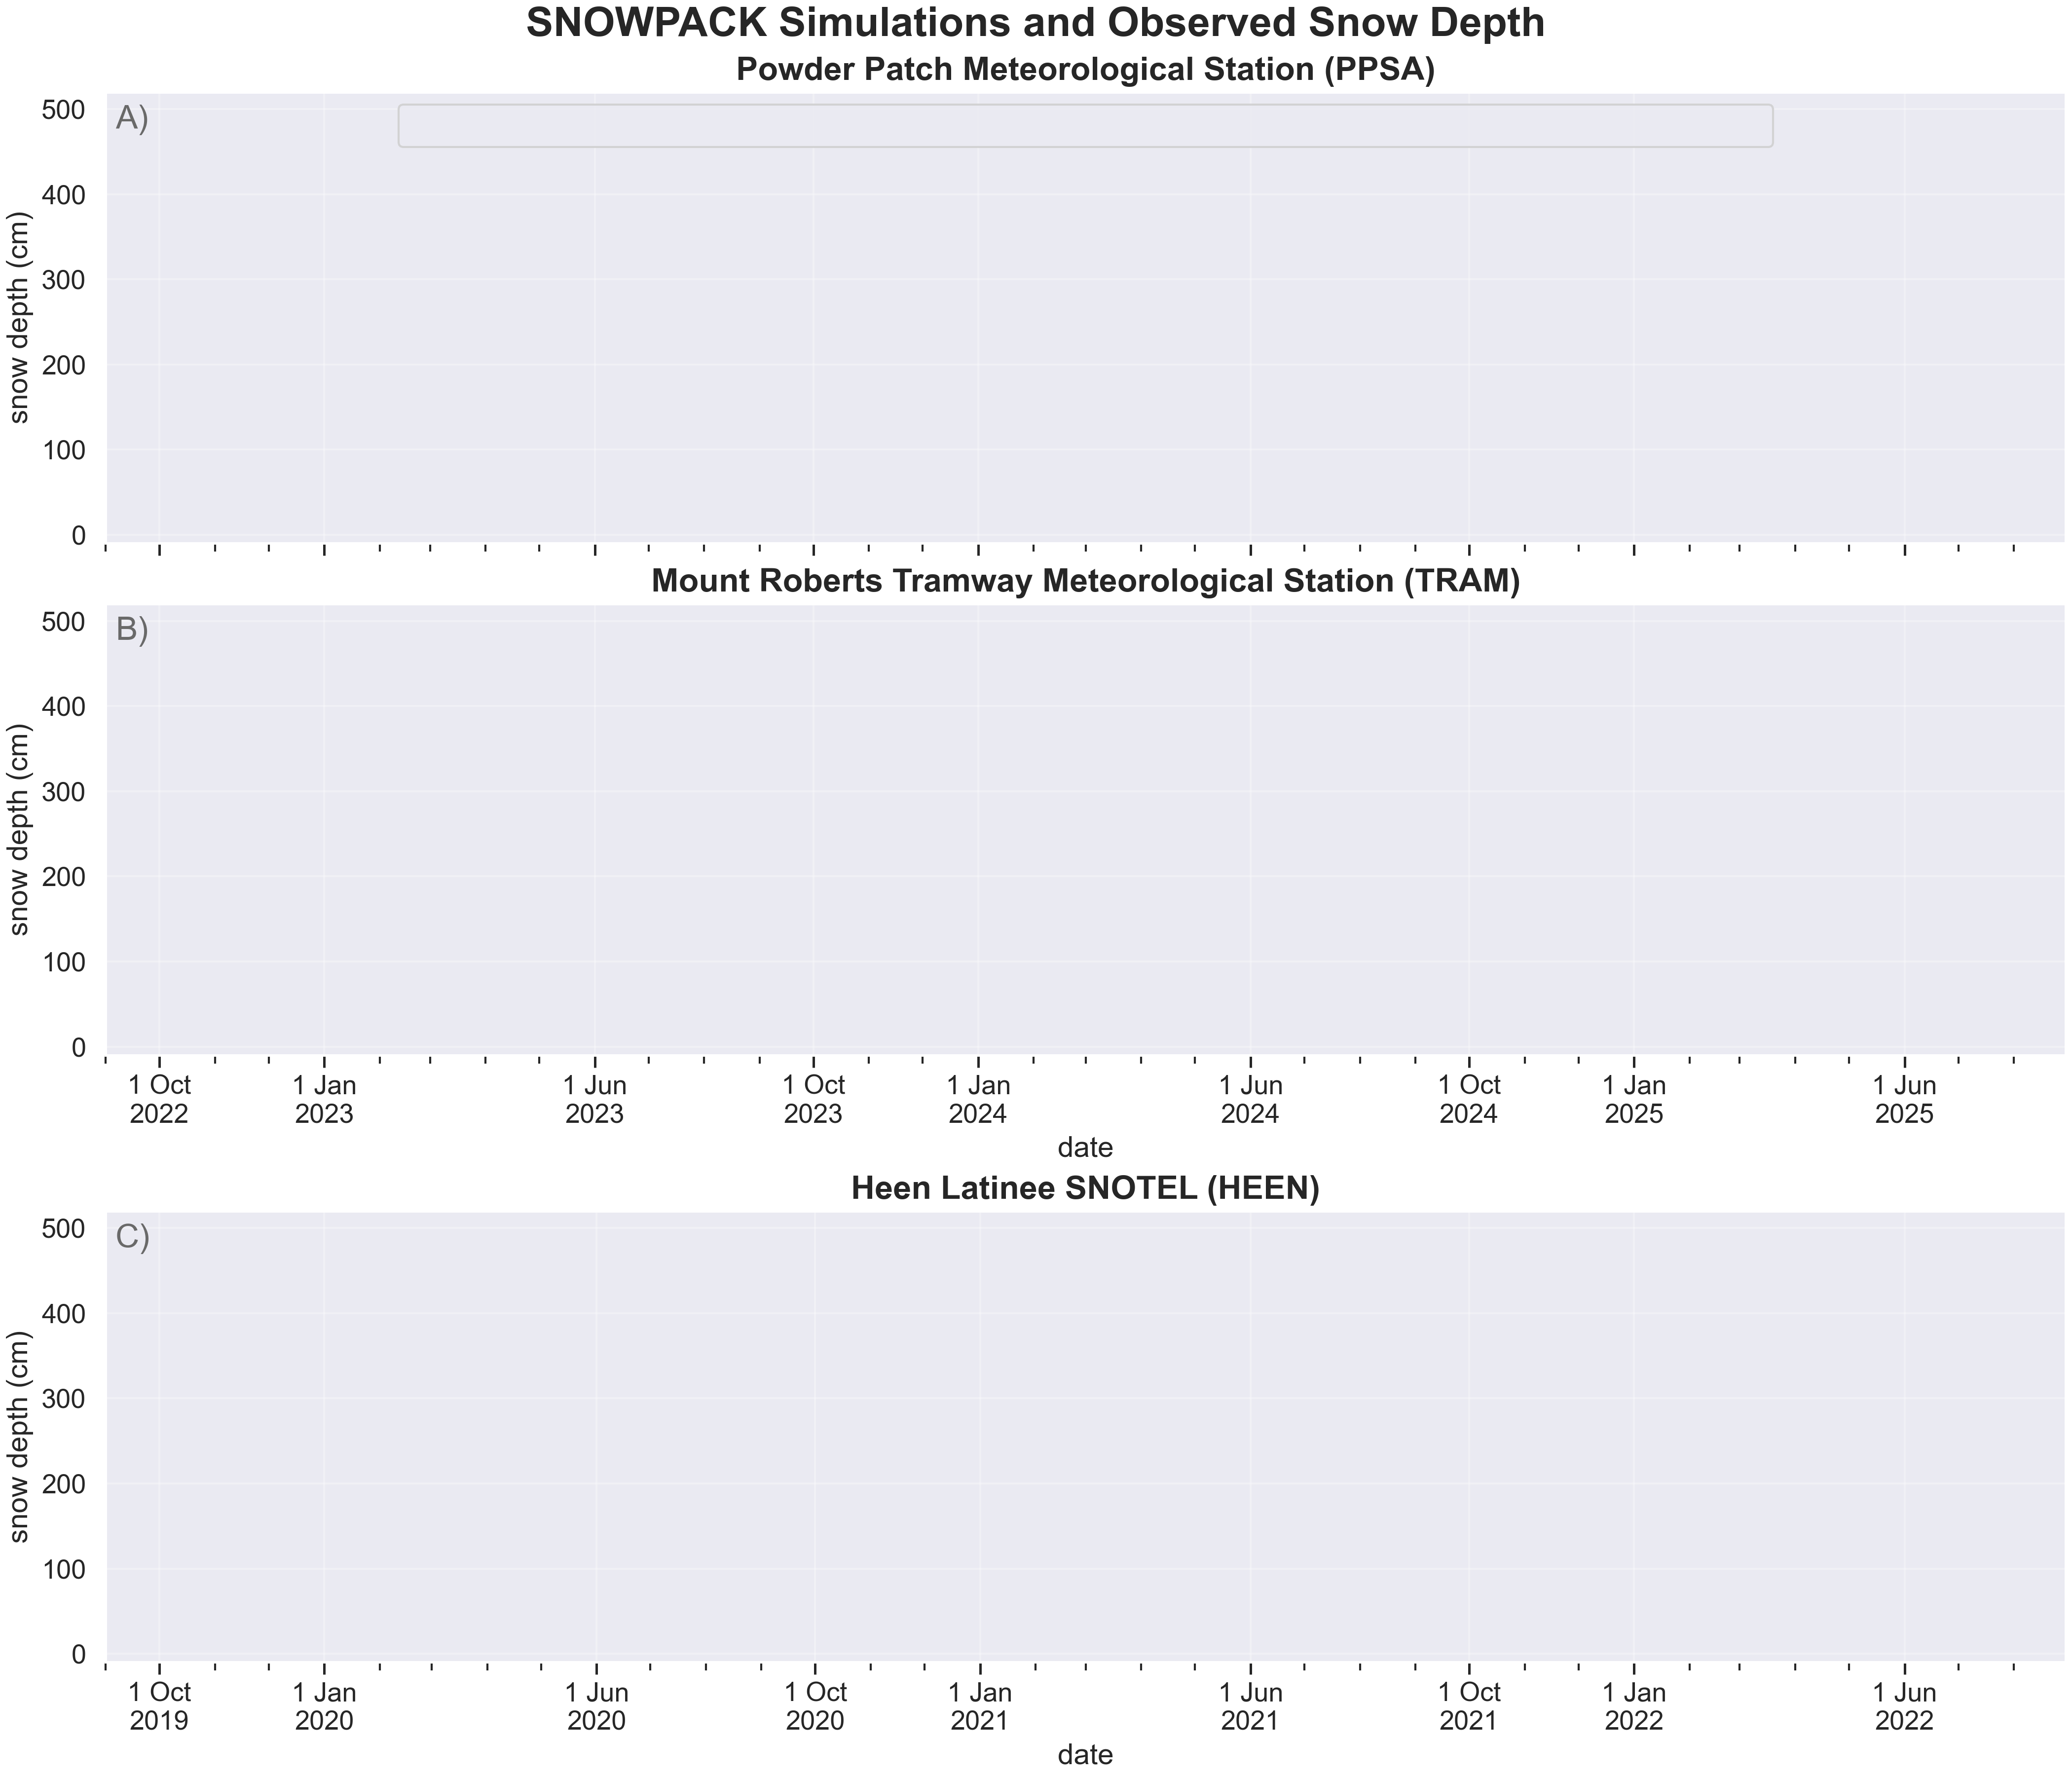

In [9]:
show_stage(0)


### Step 1 — Black observations at all sites (including snow-pit markers)


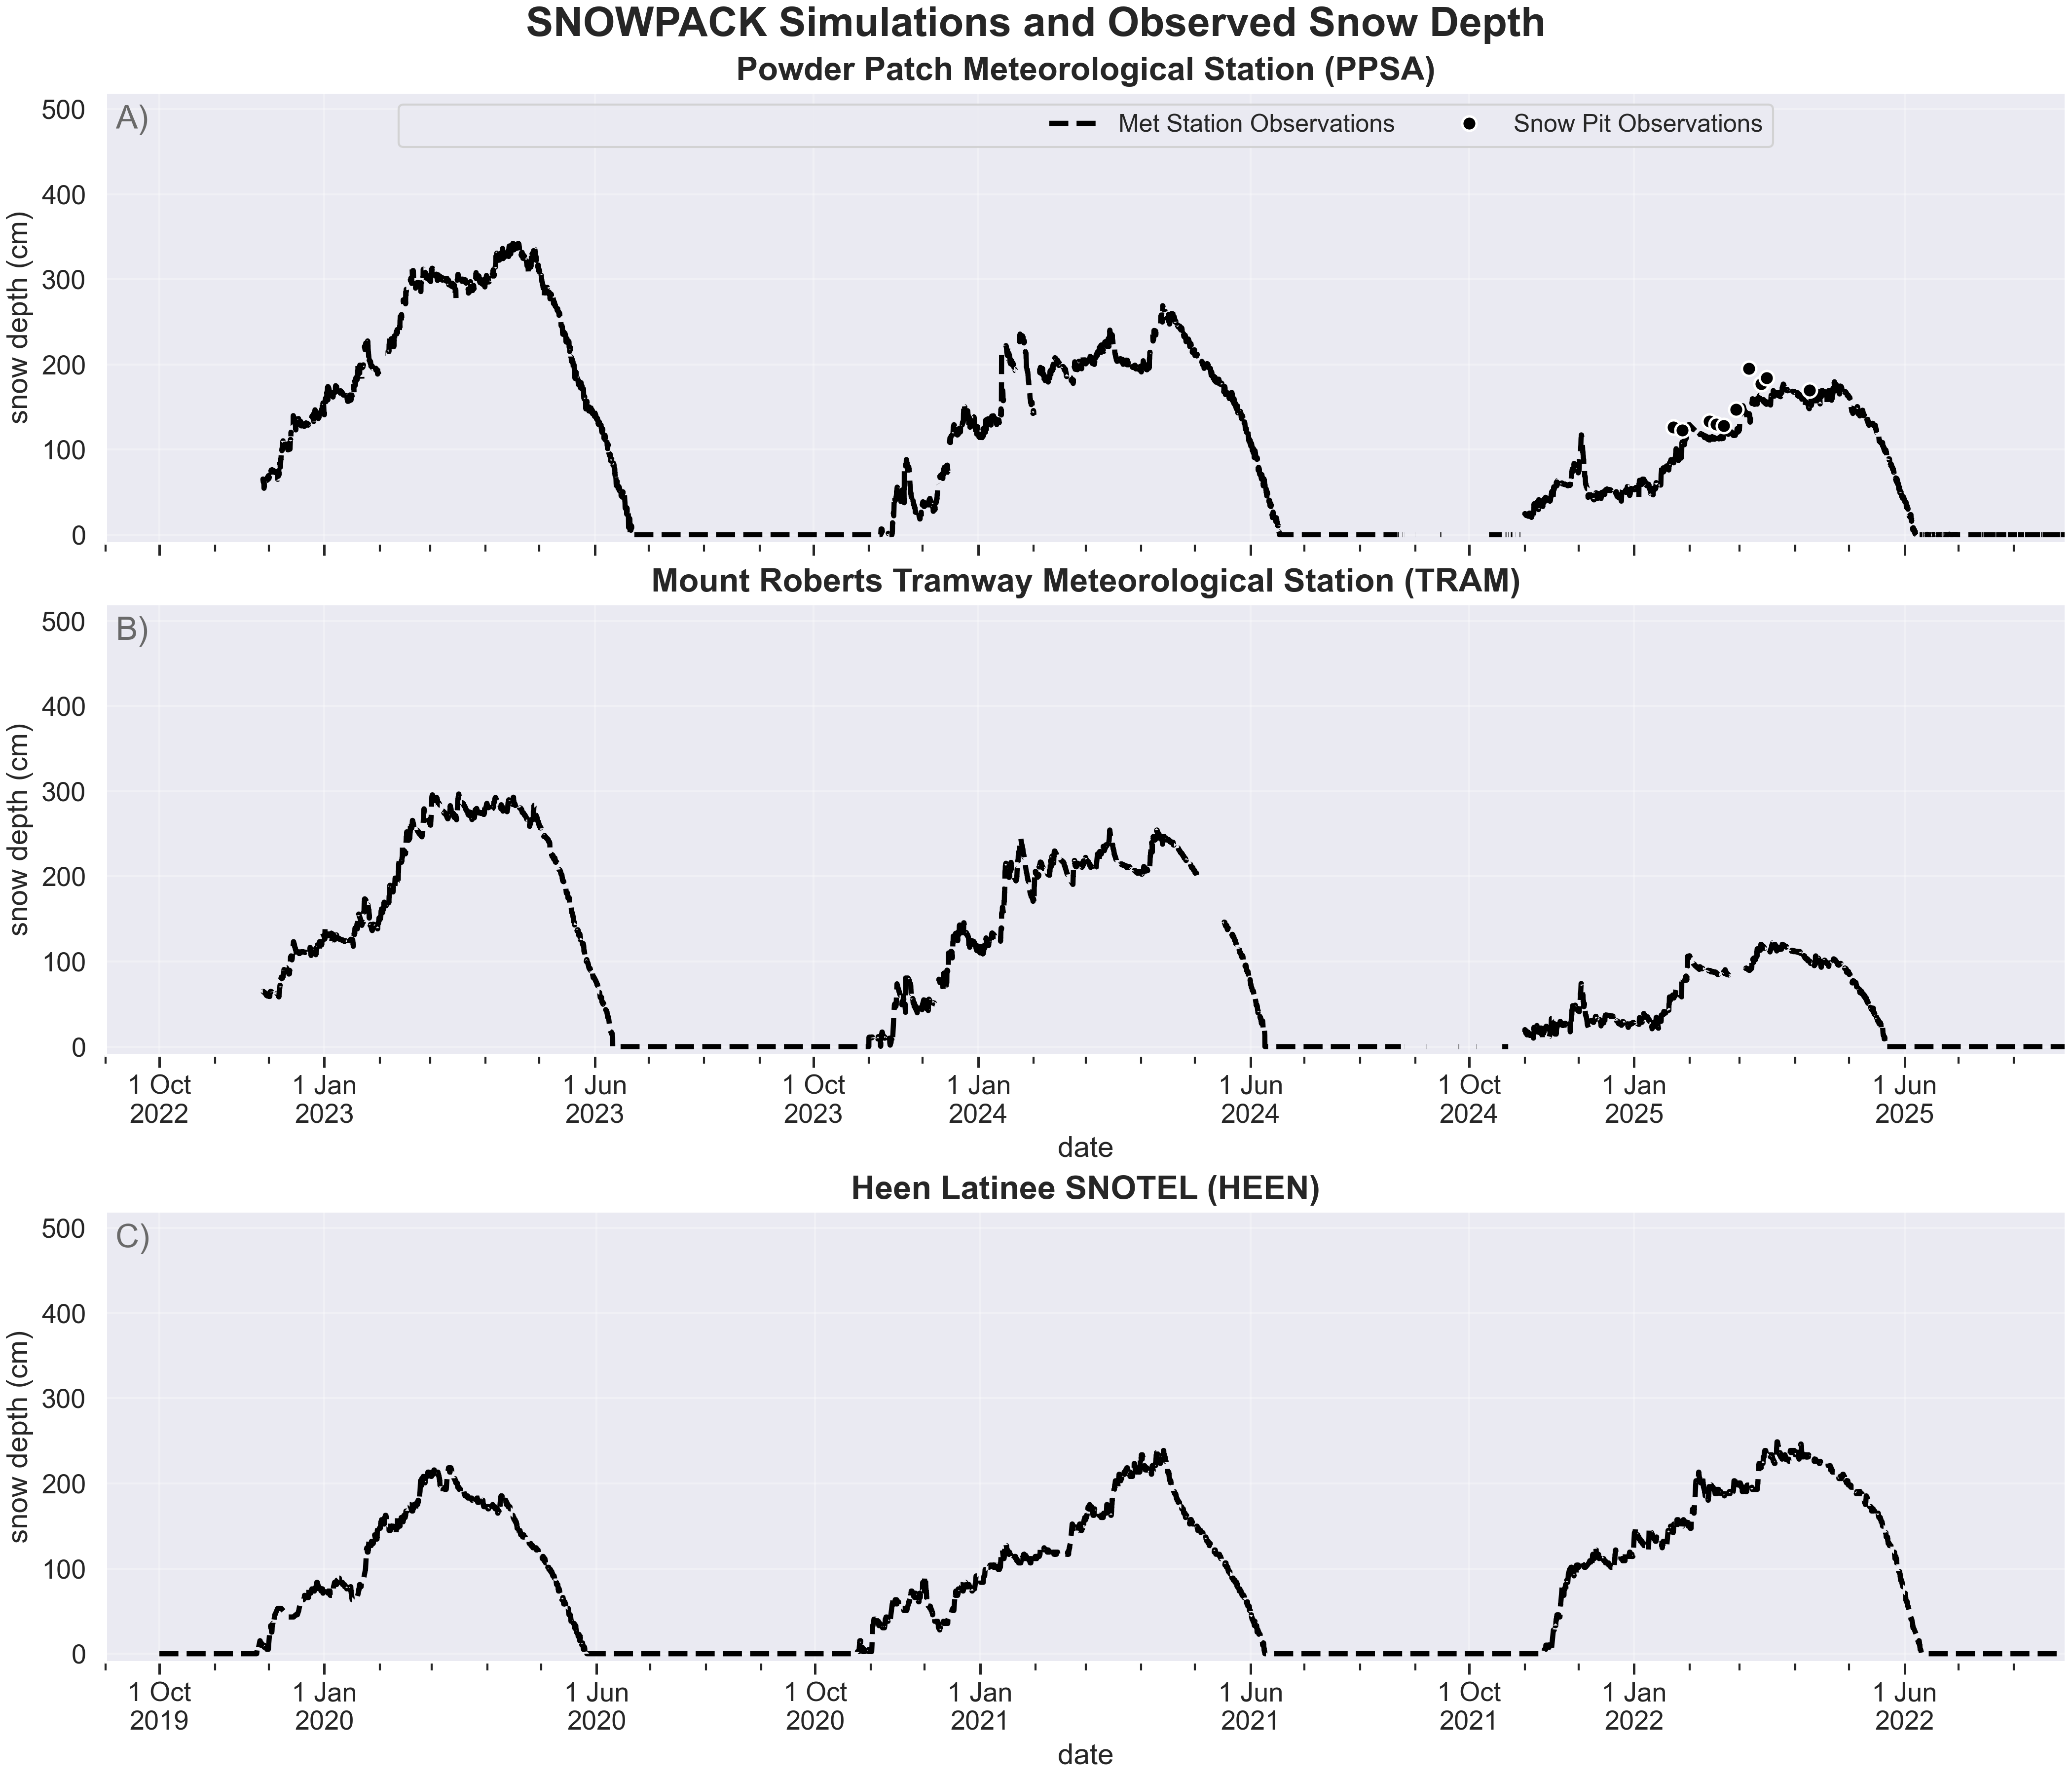

In [10]:
show_stage(1)


### Step 2 — Add blue HRRR-AK forcing at all sites


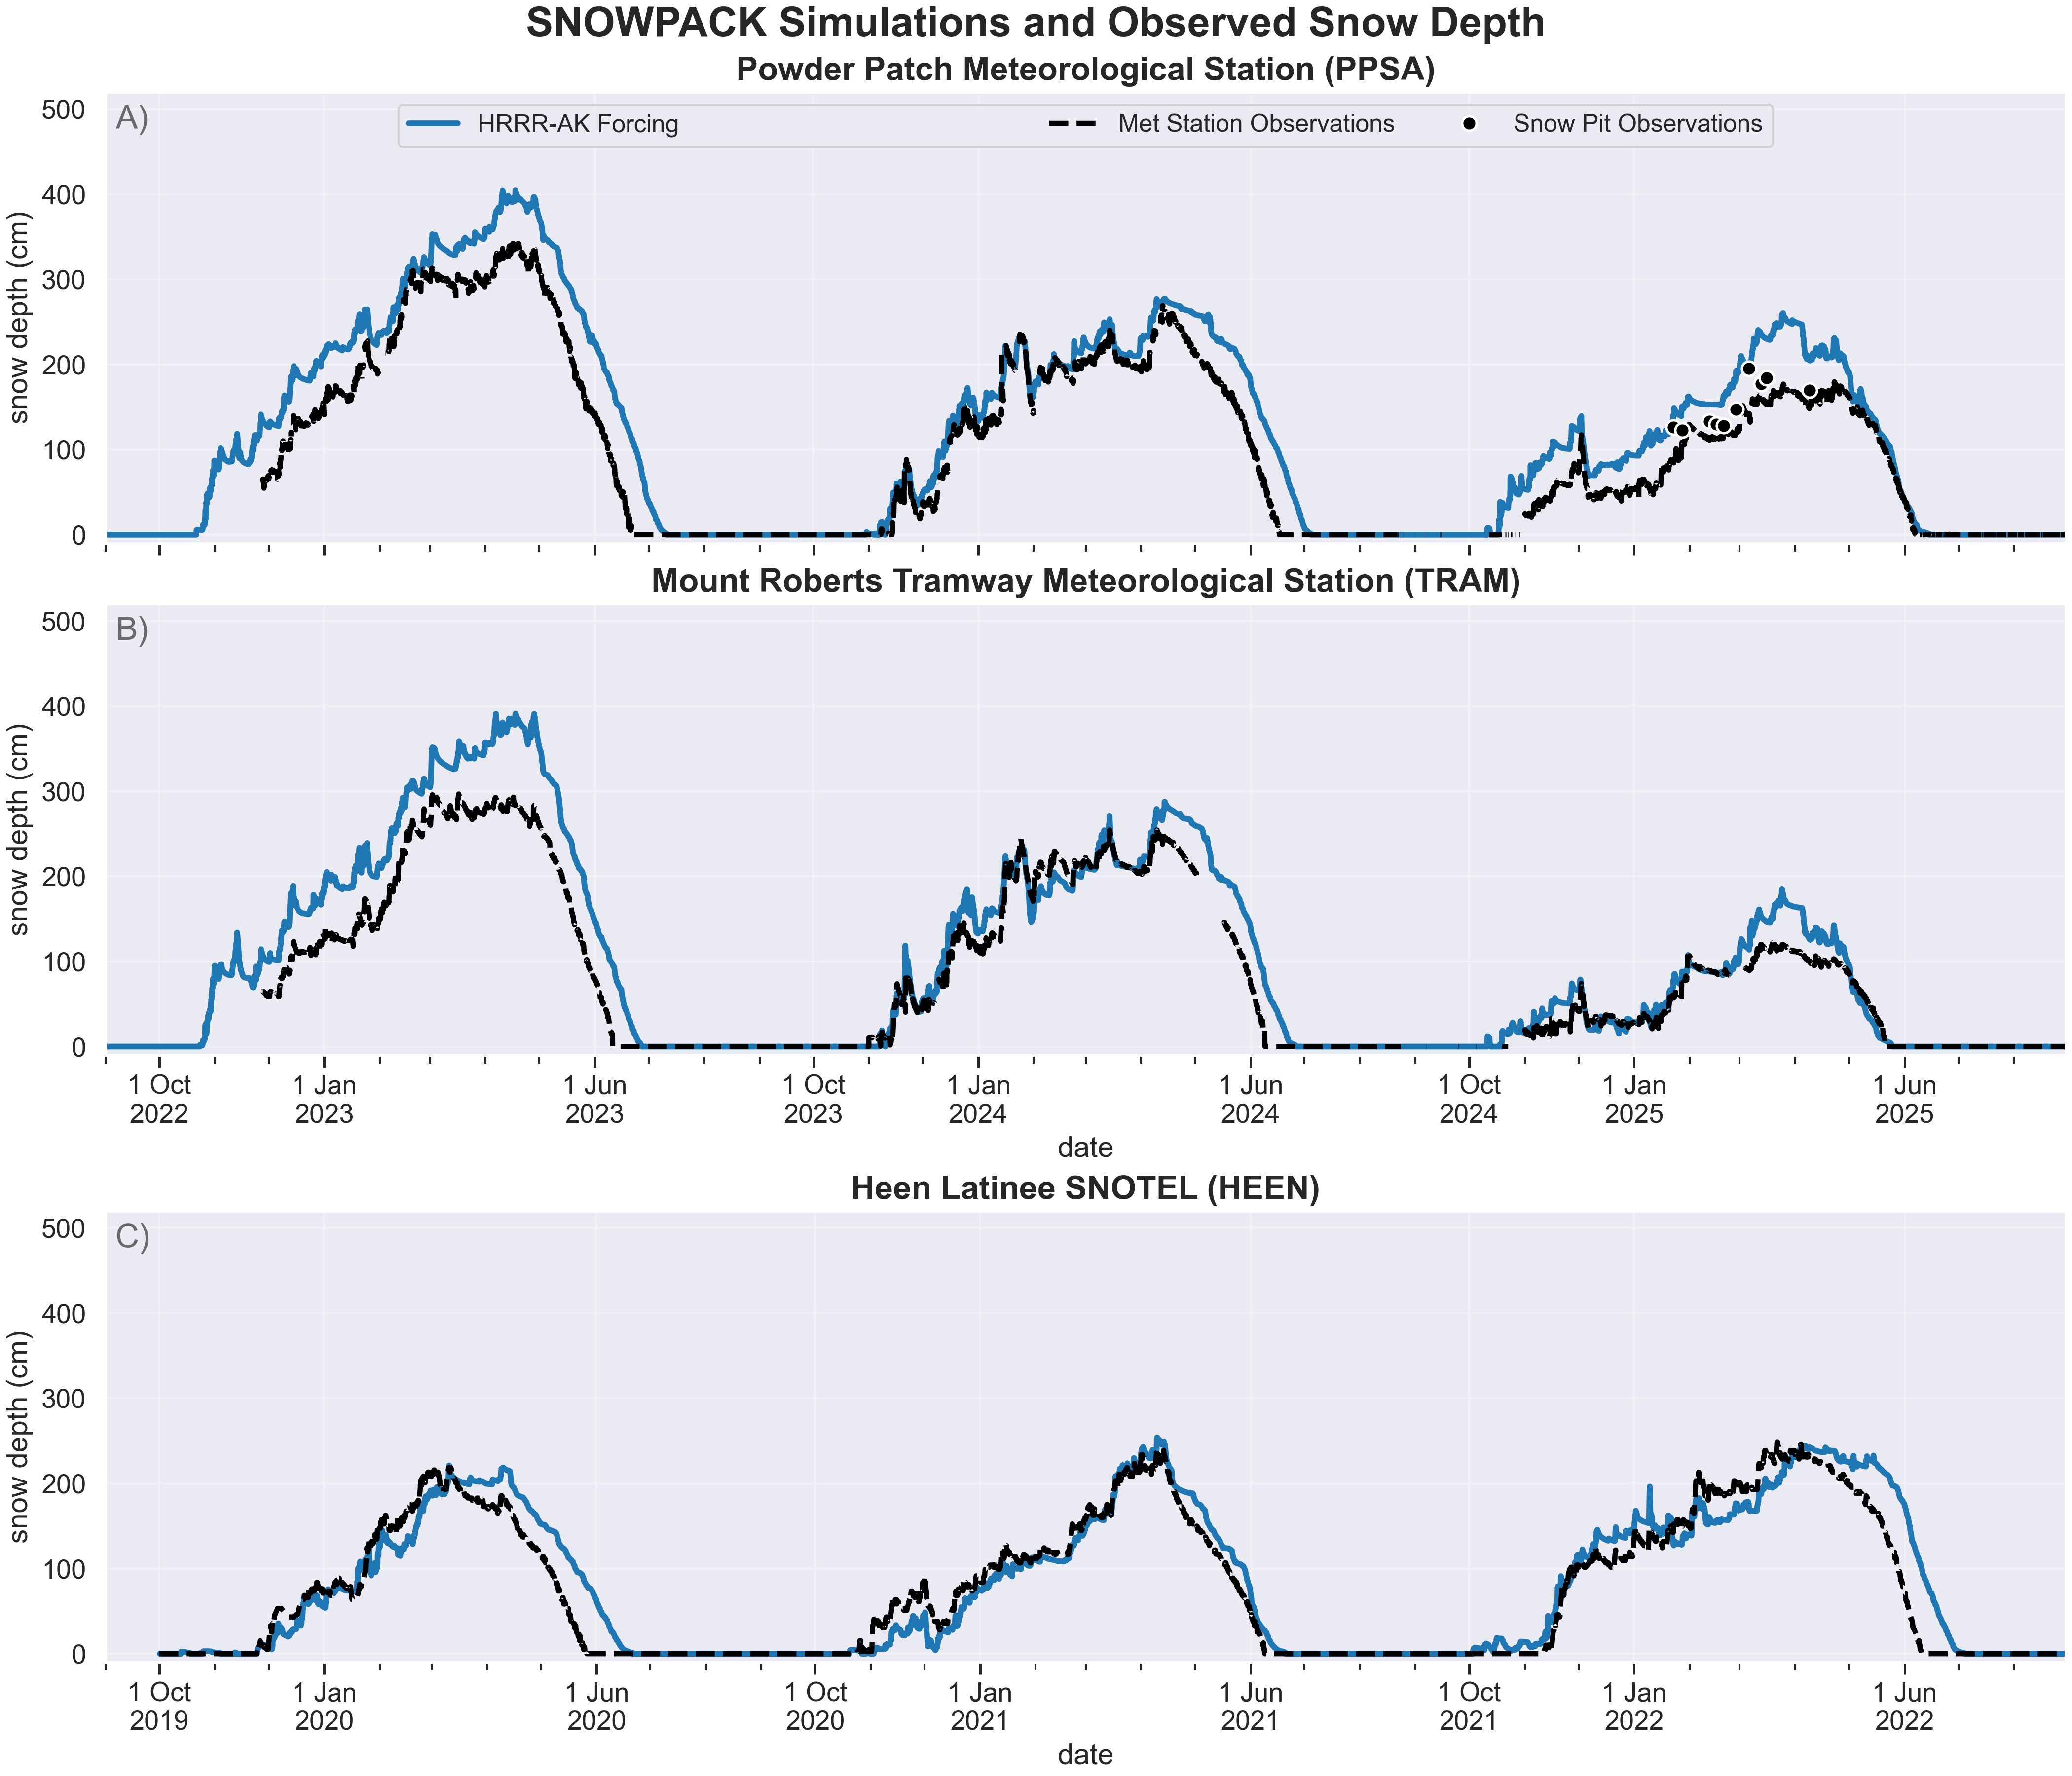

In [11]:
show_stage(2)


### Step 3 — Add green mixed-met forcing at all sites (complete Figure 4)


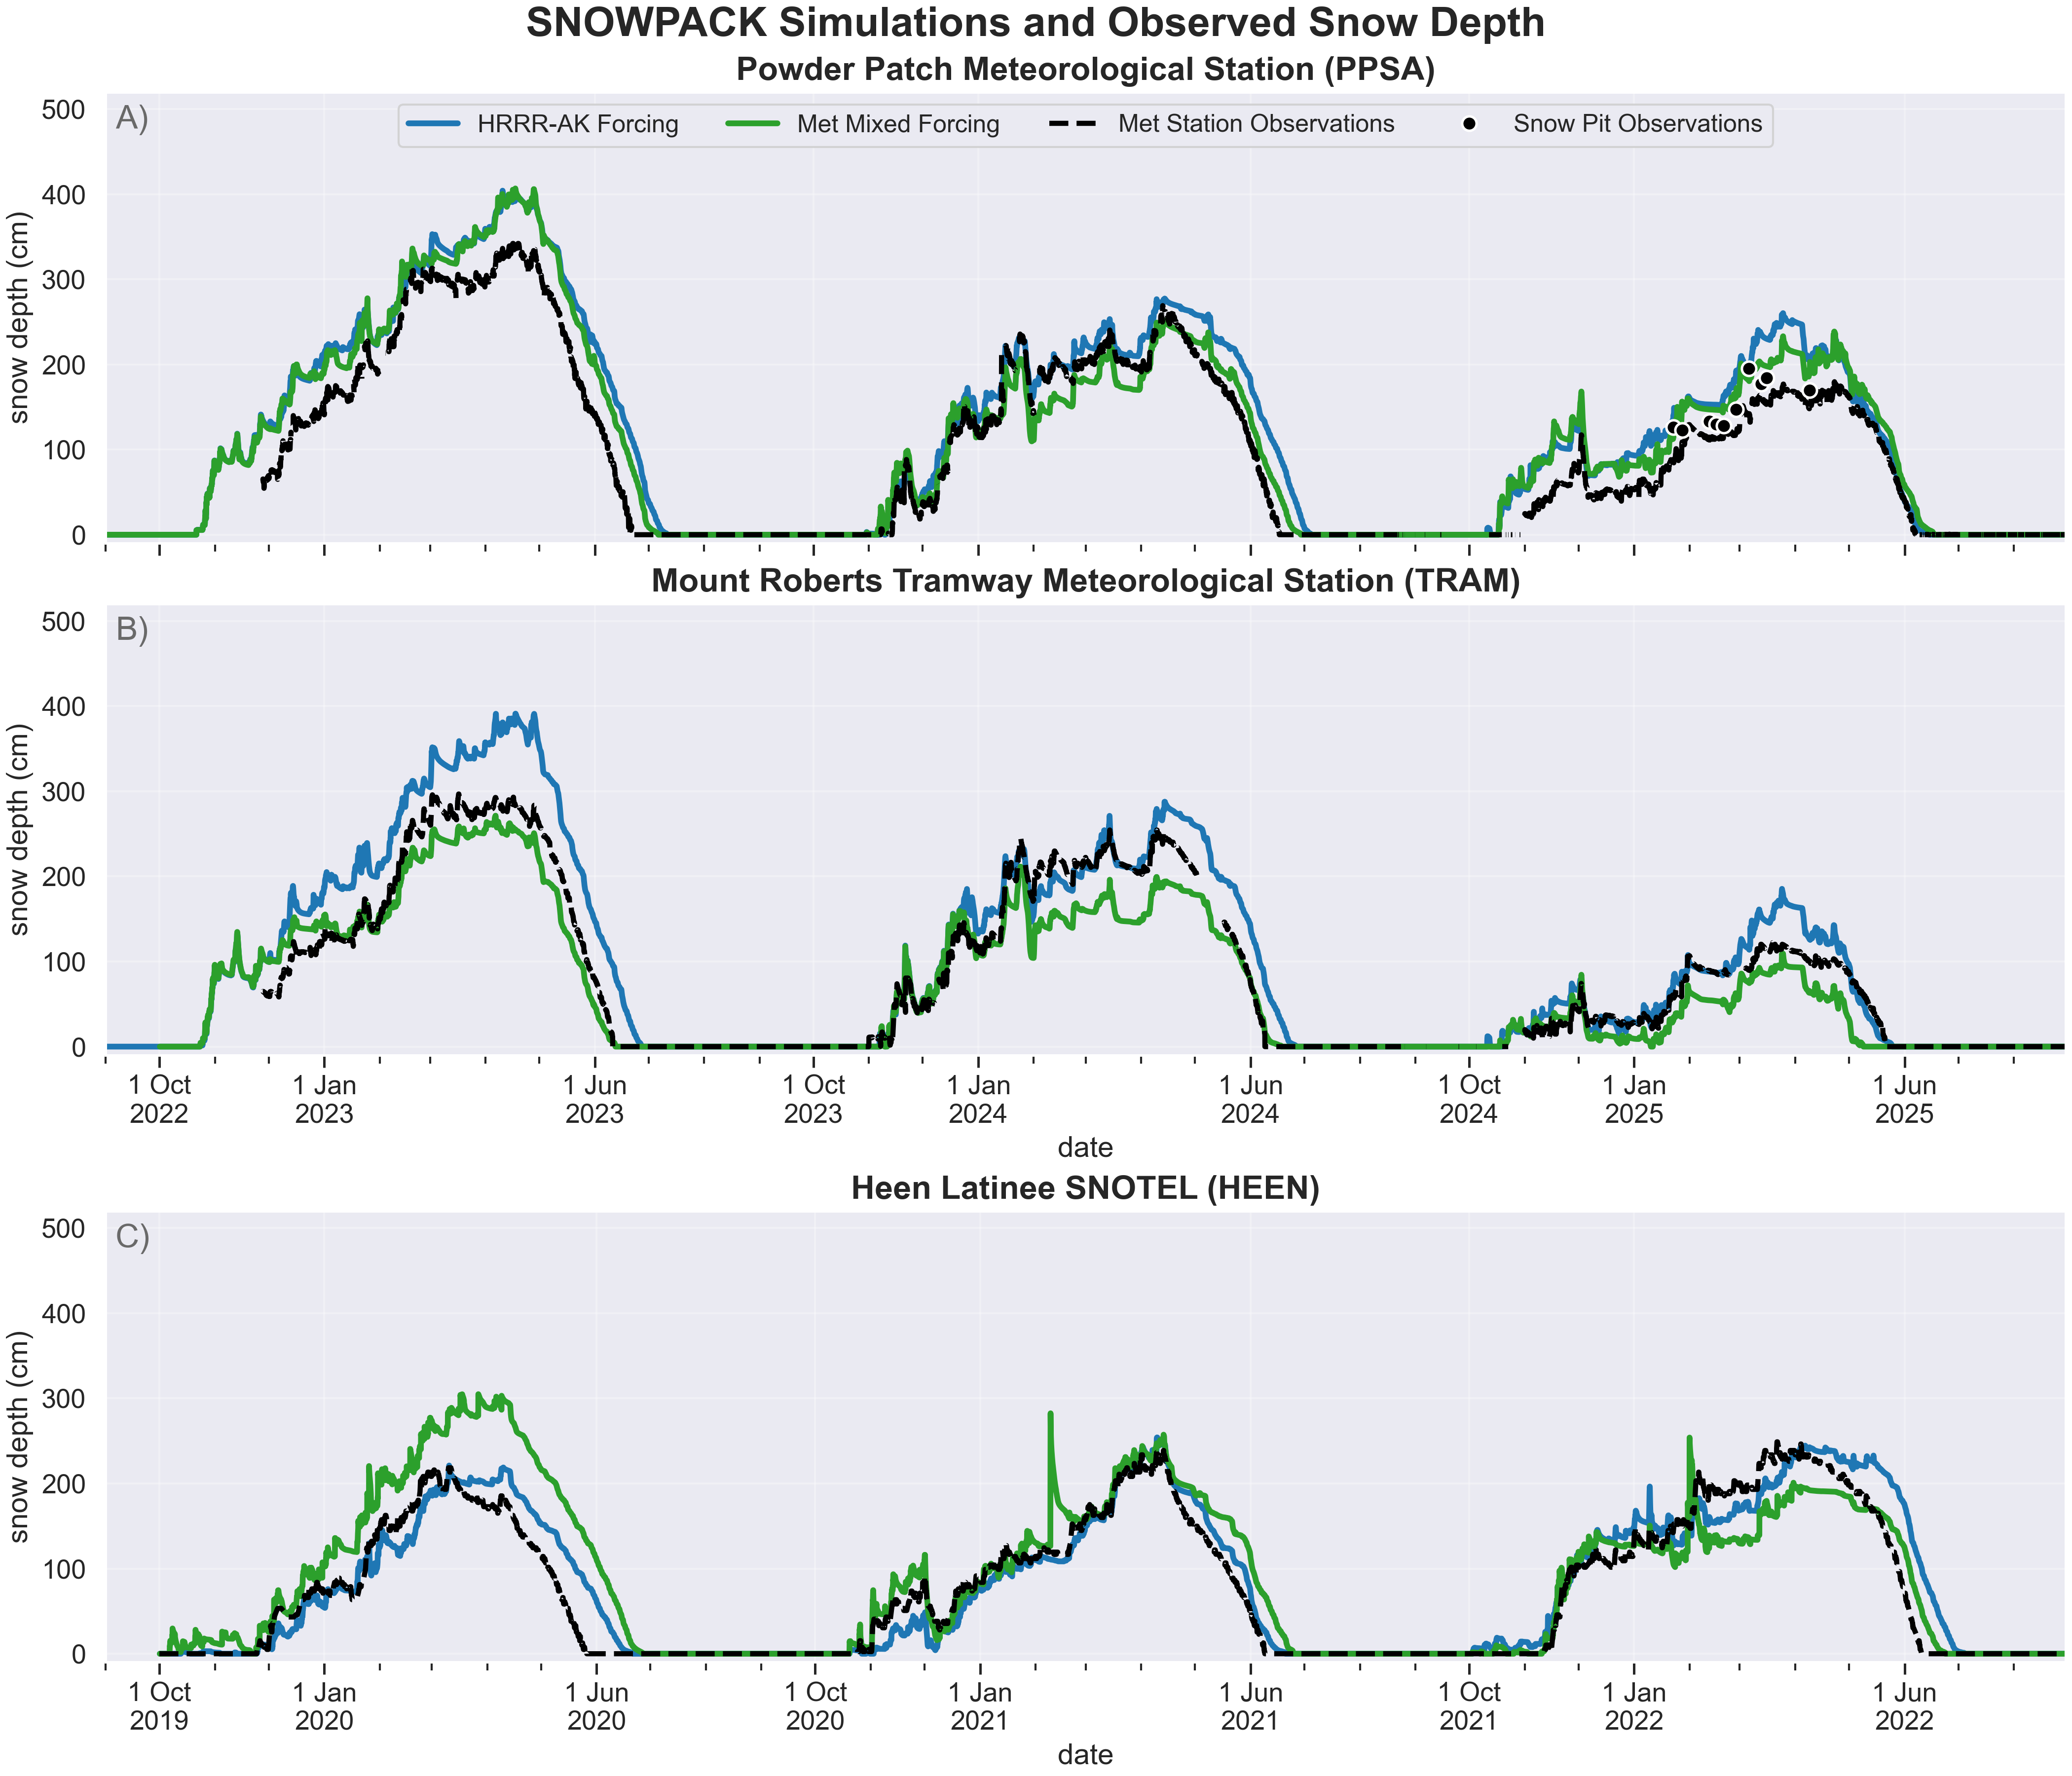

In [12]:
show_stage(3)
